<a href="https://colab.research.google.com/github/mateonmy/IA-P69/blob/main/Practica_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UNIVERSIDAD POLITÉCNICA SALESIANA
**Carrera:** Computación  
**Asignatura:** Inteligencia Artificial  
**Docente:** Ing. Rodrigo Tufiño, MSc.  
**Práctica 03:** El Perceptrón  
**Estudiante:** Mateo Zaik Samueza Vásquez

In [ ]:
import random
import matplotlib.pyplot as plt

random.seed(10)

## Fase 1. Exploración del Dataset
### 1.1 Carga del Dataset y Actividad 1.a - Inspección inicial

In [ ]:
X = [
    [1, 7], [1, 3], [3, 4], [4, 6], [4, 2],
    [6, 6], [6, 2], [6, 0], [7, 4], [9, 3],
    [9, 1], [11, 1], [12, 3], [16, 2],
    [4, 8], [6, 8], [8, 9], [9, 7], [10, 11],
    [12, 9], [12, 6], [14, 7], [16, 4]
]

y = [
    -1, -1, -1, -1, -1,
    -1, -1, -1, -1, -1,
    -1, -1, -1, -1,
     1,  1,  1,  1,  1,
     1,  1,  1,  1
]

# Conteo con ciclos simples
total_instancias = 0
for fila in X:
    total_instancias = total_instancias + 1

variables_entrada = 0
for valor in X[0]:
    variables_entrada = variables_entrada + 1

clase_negativa = 0
clase_positiva = 0
clases = []

for etiqueta in y:
    if etiqueta not in clases:
        clases.append(etiqueta)
    if etiqueta == -1:
        clase_negativa = clase_negativa + 1
    else:
        clase_positiva = clase_positiva + 1

print("Número total de instancias:", total_instancias)
print("Variables de entrada:", variables_entrada)
print("Número de clases:", len(clases))
print("Puntos clase -1:", clase_negativa)
print("Puntos clase +1:", clase_positiva)

Número total de instancias: 23
Variables de entrada: 2
Número de clases: 2
Puntos clase -1: 14
Puntos clase +1: 9


**Preguntas guía (Actividad 1.a):**
* **¿Qué representa cada fila de X?** Representa un punto o instancia con sus coordenadas $[x_1, x_2]$.
* **¿Qué representa cada valor del vector y?** Representa la clase o etiqueta real ($-1$ o $1$) a la que pertenece cada punto de `X`.
* **¿Por qué este problema se considera de clasificación binaria?** Porque solo existen dos clases posibles para clasificar los datos.

### Actividad 1.b - Separación visual de las clases

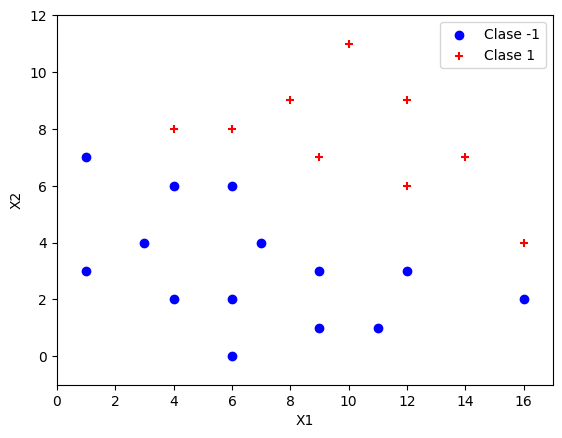

In [ ]:
def graficar_puntos(X, y):
    x1_neg = []
    x2_neg = []
    x1_pos = []
    x2_pos = []

    for i in range(len(X)):
        if y[i] == -1:
            x1_neg.append(X[i][0])
            x2_neg.append(X[i][1])
        else:
            x1_pos.append(X[i][0])
            x2_pos.append(X[i][1])

    plt.scatter(x1_neg, x2_neg, color='blue', marker='o', label='Clase -1')
    plt.scatter(x1_pos, x2_pos, color='red', marker='+', label='Clase 1')
    plt.xlim(0, 17)
    plt.ylim(-1, 12)
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.legend()
    plt.show()

graficar_puntos(X, y)

**Pregunta guía (Actividad 1.b):**
* **Observando únicamente la gráfica, ¿parece posible separar las dos clases mediante una sola recta? Justifica tu respuesta.**  
  Sí es posible, porque los puntos azules (clase -1) están en la parte inferior izquierda y las cruces rojas (clase 1) están en la parte superior derecha sin mezclarse entre sí.

## Fase 2. Fundamento del Perceptrón
### Actividades 2.a, 2.b y 2.c

In [ ]:
# Actividad 2.a: Vector de pesos
def initialize_weights():
    w0 = random.uniform(-0.5, 0.5)
    w1 = random.uniform(-0.5, 0.5)
    w2 = random.uniform(-0.5, 0.5)
    return [w0, w1, w2]

# Actividad 2.b: Función de activación
def activation(z):
    if z >= 0:
        return 1
    else:
        return -1

# Actividad 2.c: Cálculo de salida
def perceptron_compute(x, w):
    z = w[0] + w[1] * x[0] + w[2] * x[1]
    salida = activation(z)
    return salida

# Prueba manual con 3 instancias del dataset
w_prueba = initialize_weights()
print("Pesos de prueba:", w_prueba)
print("Prueba instancia X[0]:", X[0], "-> Predicción:", perceptron_compute(X[0], w_prueba), "| Real:", y[0])
print("Prueba instancia X[5]:", X[5], "-> Predicción:", perceptron_compute(X[5], w_prueba), "| Real:", y[5])
print("Prueba instancia X[15]:", X[15], "-> Predicción:", perceptron_compute(X[15], w_prueba), "| Real:", y[15])

Pesos de prueba: [0.0714025946899135, -0.07111094532488538, 0.07809130113447038]
Prueba instancia X[0]: [1, 7] -> Predicción: 1 | Real: -1
Prueba instancia X[5]: [6, 6] -> Predicción: 1 | Real: -1
Prueba instancia X[15]: [6, 8] -> Predicción: 1 | Real: 1


**Preguntas guía (Fase 2):**
* **Actividad 2.a - ¿Por qué el vector de pesos tiene tres valores si cada instancia de entrada solo tiene dos variables? ¿Qué función cumple el bias en el modelo?**  
  Porque incluye dos pesos para las entradas ($w_1, w_2$) y un peso adicional ($w_0$) para el bias. El bias sirve para poder mover o desplazar la recta y que no tenga que pasar obligatoriamente por el origen $(0,0)$.
* **Actividad 2.b - ¿Por qué en esta práctica se utilizan las etiquetas -1 y 1 en lugar de 0 y 1? ¿Qué ventaja tiene esta representación para el algoritmo del perceptrón?**  
  Porque al usar $-1$ y $1$ la actualización de pesos es simétrica alrededor de cero y permite corregir los pesos hacia ambos lados con la misma magnitud cuando ocurre un error.
* **Actividad 2.c - ¿Cuál es la diferencia entre la suma ponderada z y la salida final del perceptrón? ¿Por qué no basta con calcular solo z?**  
  La suma ponderada $z$ es cualquier número decimal, mientras que la salida final solo puede ser $-1$ o $1$. No basta con $z$ porque necesitamos predecir una clase exacta para compararla con la etiqueta real.

## Fase 3. Visualización de la Frontera de Decisión
### Actividades 3.a y 3.b

Pesos iniciales: [-0.29390176786049826, 0.31332125135732003, 0.3235888725334455]


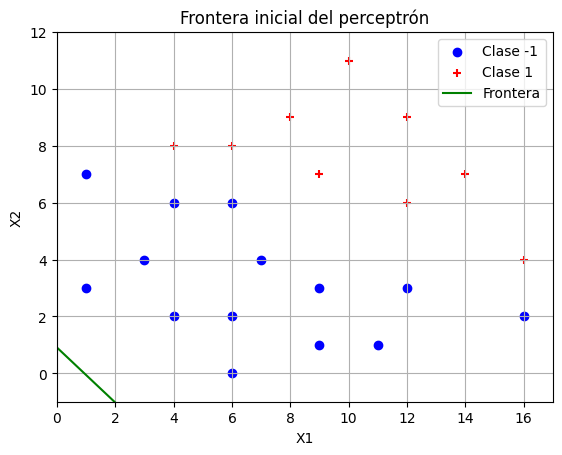

In [ ]:
# Actividad 3.a: Función de graficación
def perceptron_plot(X, y, w, title):
    x1_neg = []
    x2_neg = []
    x1_pos = []
    x2_pos = []

    for i in range(len(X)):
        if y[i] == -1:
            x1_neg.append(X[i][0])
            x2_neg.append(X[i][1])
        else:
            x1_pos.append(X[i][0])
            x2_pos.append(X[i][1])

    plt.scatter(x1_neg, x2_neg, color='blue', marker='o', label='Clase -1')
    plt.scatter(x1_pos, x2_pos, color='red', marker='+', label='Clase 1')

    # Ecuación de la recta despejando x2
    if w[2] != 0:
        x1_recta = [0, 17]
        x2_punto1 = -(w[0] + w[1] * 0) / w[2]
        x2_punto2 = -(w[0] + w[1] * 17) / w[2]
        x2_recta = [x2_punto1, x2_punto2]
        plt.plot(x1_recta, x2_recta, color='green', label='Frontera')
    else:
        print("w2 es 0, no se puede dividir para cero.")

    plt.xlim(0, 17)
    plt.ylim(-1, 12)
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

# Actividad 3.b: Gráfica con pesos iniciales
w_initial = initialize_weights()
print("Pesos iniciales:", w_initial)
perceptron_plot(X, y, w_initial, "Frontera inicial del perceptrón")

**Preguntas guía (Fase 3):**
* **Actividad 3.a - ¿Qué representa geométricamente la recta generada por el perceptrón? ¿Qué ocurre si los pesos iniciales son aleatorios?**  
  Representa el límite o frontera donde $z = 0$, dividiendo el plano en dos zonas (una para la clase $1$ y otra para la clase $-1$). Si los pesos son aleatorios, la recta aparece en cualquier dirección sin separar bien los datos.
* **Actividad 3.b - ¿La frontera inicial clasifica correctamente los puntos? ¿Por qué no deberíamos esperar que una frontera con pesos aleatorios sea correcta?**  
  No los clasifica bien. No podemos esperar que sea correcta porque los pesos se eligieron al azar y el perceptrón todavía no ha sido entrenado con los datos.

## Fase 4. Entrenamiento del Perceptrón
### Actividades 4.a, 4.b y 4.c

In [ ]:
def perceptron_learning(X, y, w, lr, max_epochs):
    # Creamos una copia simple de los pesos iniciales
    pesos = [w[0], w[1], w[2]]
    epochs = 0
    updates = 0
    W_values = []
    E_values = []

    for epoca in range(max_epochs):
        epochs = epochs + 1
        errores = 0

        for i in range(len(X)):
            x_actual = X[i]
            y_real = y[i]
            y_pred = perceptron_compute(x_actual, pesos)

            if y_real != y_pred:
                errores = errores + 1
                updates = updates + 1
                # Regla de actualización
                pesos[0] = pesos[0] + lr * (y_real - y_pred)
                pesos[1] = pesos[1] + lr * (y_real - y_pred) * x_actual[0]
                pesos[2] = pesos[2] + lr * (y_real - y_pred) * x_actual[1]

        # Actividad 4.b: Tasa de error de la época
        tasa_error = errores / len(X)
        E_values.append(tasa_error)

        # Actividad 4.c: Guardar copia de los valores de los pesos
        W_values.append([pesos[0], pesos[1], pesos[2]])

        # Si ya no hay errores, terminamos el entrenamiento
        if errores == 0:
            break

    return pesos, epochs, updates, W_values, E_values

**Preguntas guía (Fase 4):**
* **Actividad 4.a - ¿Por qué es necesario incluir un número máximo de épocas? ¿Qué podría ocurrir si el dataset no fuera linealmente separable?**  
  Para evitar que el programa se quede en un ciclo infinito. Si los datos no se pudieran separar con una recta, nunca habría cero errores y el entrenamiento nunca terminaría sin un límite de épocas.
* **Actividad 4.b - ¿Qué significa que la tasa de error llegue a cero?**  
  Significa que el perceptrón clasificó correctamente todos los puntos del dataset en esa época sin equivocarse en ninguno.
* **Actividad 4.c - ¿Por qué es importante guardar copias de los pesos y no solo el vector w? ¿Qué problema aparecería al intentar graficar la evolución del entrenamiento?**  
  Porque en Python si guardamos la misma lista `w` sin copiar sus valores, todas las posiciones de `W_values` terminarían teniendo exactamente los mismos pesos finales y todas las gráficas de evolución saldrían iguales.

## Fase 5. Entrenamiento con tasa de aprendizaje 0.5
### Actividades 5.a y 5.b

Pesos iniciales: [0.0714025946899135, -0.07111094532488538, 0.07809130113447038]
Pesos finales: [-26.928597405310086, 0.9288890546751141, 3.078091301134471]
Número de épocas: 44
Número total de actualizaciones: 123
Error final: 0.0


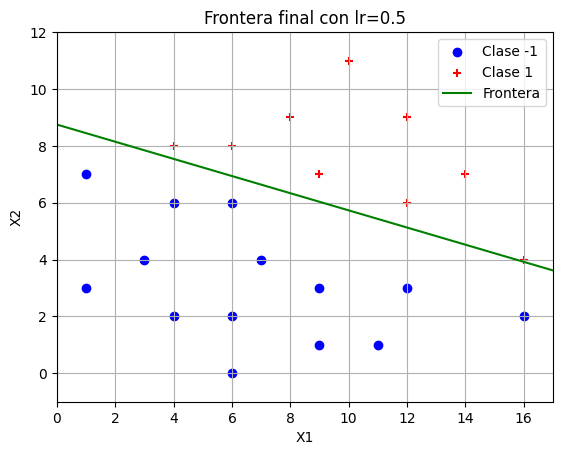

In [ ]:
random.seed(10)
w = initialize_weights()

final_w, epochs, updates, W_values, E_values = perceptron_learning(
    X, y, w, lr=0.5, max_epochs=1000
)

print("Pesos iniciales:", w)
print("Pesos finales:", final_w)
print("Número de épocas:", epochs)
print("Número total de actualizaciones:", updates)
print("Error final:", E_values[-1])

# Actividad 5.b: Frontera final
perceptron_plot(X, y, final_w, "Frontera final con lr=0.5")

**Preguntas guía (Fase 5):**
* **Actividad 5.a - ¿El perceptrón logró converger? ¿Cómo puedes comprobarlo usando la lista E_values y la gráfica final?**  
  Sí logró converger en 44 épocas. Se comprueba porque el último valor de `E_values` es `0.0` y en la gráfica la recta verde deja a todas las cruces rojas arriba y a todos los puntos azules abajo.
* **Actividad 5.b - ¿La frontera final separa correctamente las dos clases? ¿Qué diferencias observas respecto a la frontera inicial?**  
  Sí las separa correctamente. A diferencia de la frontera inicial que estaba en una esquina inferior, la frontera final subió y cambió su inclinación hasta ubicarse justo en medio de las dos clases.

## Fase 6. Predicción con Nuevas Instancias
### Actividades 6.a y 6.b

Instancia  | Salida predicha
----------------------------
[5, 5]    | -1
[10, 6]    | 1
[6, 10]    | 1


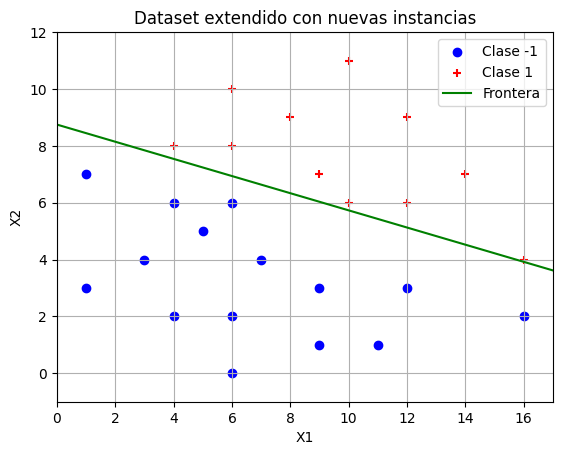

In [ ]:
X_test = [
    [5, 5],
    [10, 6],
    [6, 10]
]

# Actividad 6.a: Clasificación de nuevas instancias
salidas_test = []
print("Instancia  | Salida predicha")
print("----------------------------")
for punto in X_test:
    prediccion = perceptron_compute(punto, final_w)
    salidas_test.append(prediccion)
    print(punto, "   |", prediccion)

# Actividad 6.b: Dataset extendido
X_extendido = []
y_extendido = []

for i in range(len(X)):
    X_extendido.append(X[i])
    y_extendido.append(y[i])

for i in range(len(X_test)):
    X_extendido.append(X_test[i])
    y_extendido.append(salidas_test[i])

perceptron_plot(X_extendido, y_extendido, final_w, "Dataset extendido con nuevas instancias")

**Preguntas guía (Fase 6):**
* **Actividad 6.a - ¿Las predicciones obtenidas son coherentes con la ubicación visual de los puntos respecto a la frontera de decisión?**  
  Sí, porque `[5, 5]` queda por debajo de la recta (clase -1), mientras que `[10, 6]` y `[6, 10]` quedan por encima de la recta (clase 1).
* **Actividad 6.b - ¿Las nuevas instancias quedaron ubicadas en la región esperada del plano? ¿Alguna predicción parece discutible? Justifica tu respuesta.**  
  Sí quedaron en su región, pero la predicción de `[10, 6]` es discutible porque ese punto cae muy cerca de la recta de separación. Si la recta tuviera una inclinación un poco distinta, podría clasificarse como -1.

## Fase 7. Evolución de la Frontera de Decisión
### Actividades 7.a y 7.b

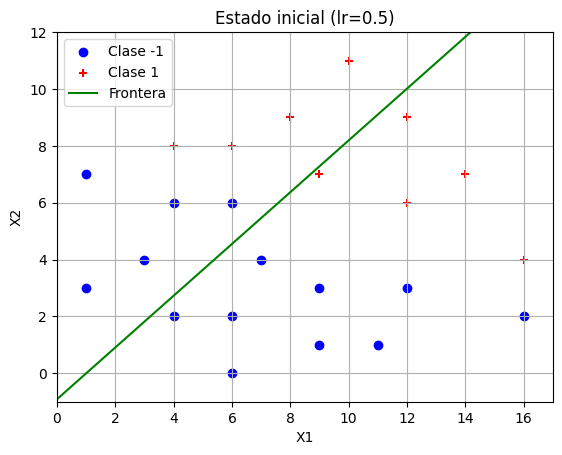

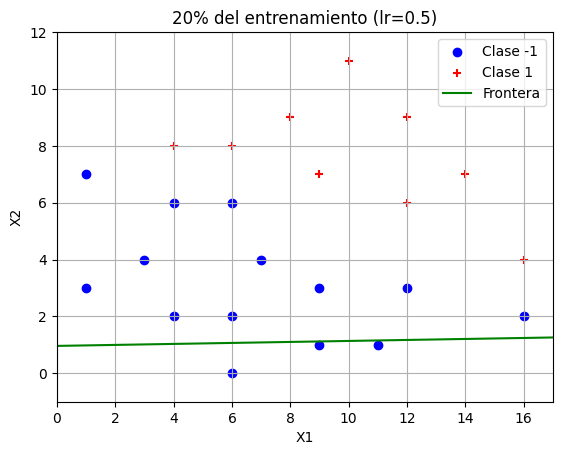

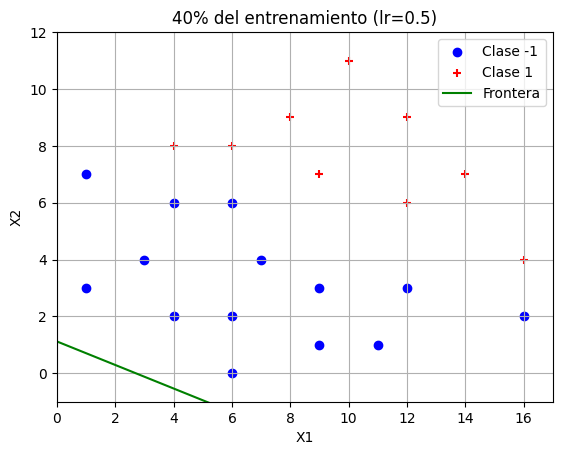

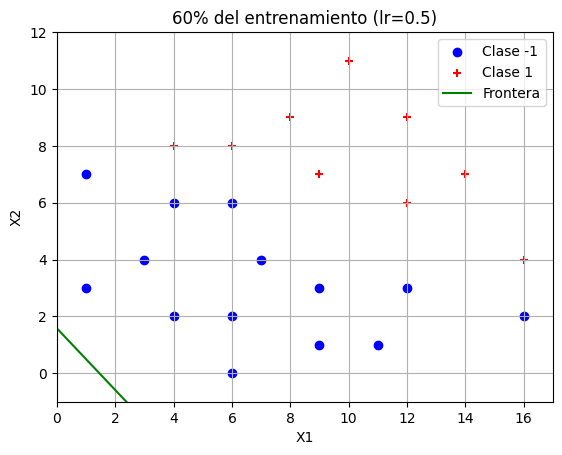

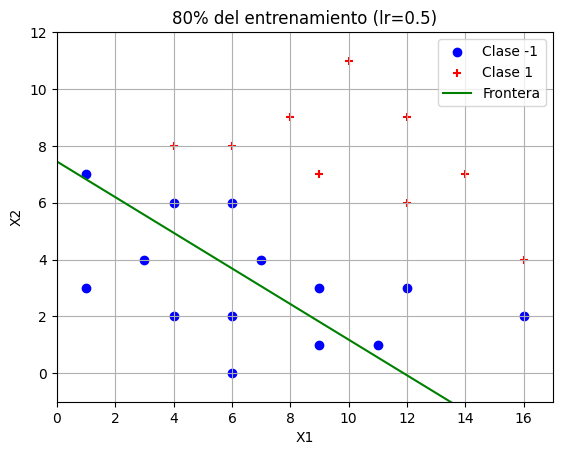

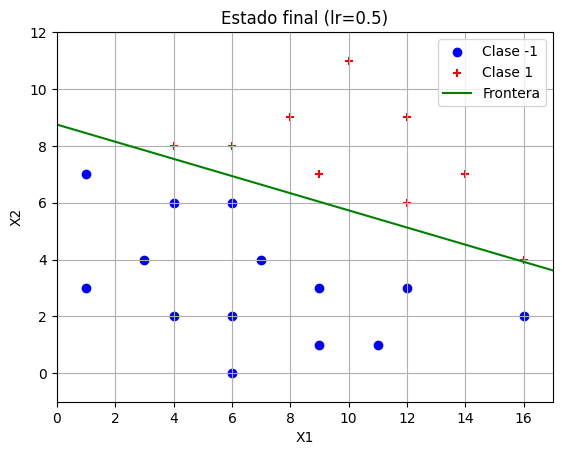

In [ ]:
def graficar_seis_estados(X, y, w_inicial, W_values, texto_lr):
    n = len(W_values)
    # Seleccionamos el estado inicial y los porcentajes de avance
    estados_pesos = [
        w_inicial,
        W_values[int(n * 0.2) - 1],
        W_values[int(n * 0.4) - 1],
        W_values[int(n * 0.6) - 1],
        W_values[int(n * 0.8) - 1],
        W_values[n - 1]
    ]
    titulos = [
        "Estado inicial (" + texto_lr + ")",
        "20% del entrenamiento (" + texto_lr + ")",
        "40% del entrenamiento (" + texto_lr + ")",
        "60% del entrenamiento (" + texto_lr + ")",
        "80% del entrenamiento (" + texto_lr + ")",
        "Estado final (" + texto_lr + ")"
    ]

    for k in range(6):
        perceptron_plot(X, y, estados_pesos[k], titulos[k])

graficar_seis_estados(X, y, w, W_values, "lr=0.5")

**Preguntas guía (Fase 7):**
* **Actividad 7.a - ¿Qué ocurre con la frontera de decisión a medida que se actualizan los pesos? ¿El cambio parece estable o brusco?**  
  La recta va cambiando su inclinación y subiendo poco a poco hasta separar los grupos. En las primeras épocas el cambio es brusco porque hay varios errores, y al final se vuelve más estable.
* **Actividad 7.b - ¿Qué peso parece influir más en la inclinación de la recta? ¿Qué papel parece cumplir el bias en el desplazamiento de la frontera?**  
  Los pesos $w_1$ y $w_2$ controlan la inclinación (pendiente) de la recta, mientras que el bias ($w_0$) se encarga de subir o bajar la recta en el plano cartesiano.

## Fase 8. Evolución del Error
### Actividades 8.a y 8.b

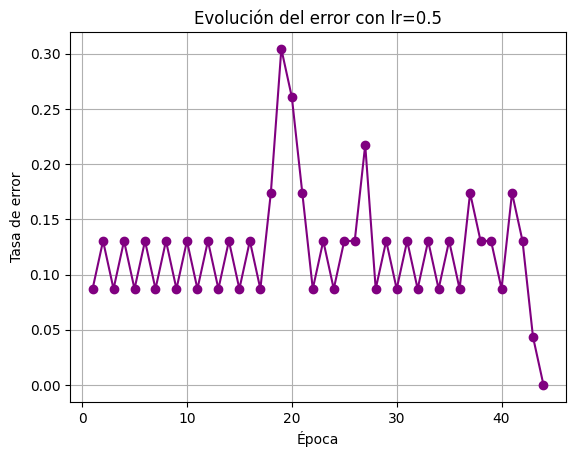

In [ ]:
def plot_error(E_values, title):
    epocas_lista = []
    for i in range(len(E_values)):
        epocas_lista.append(i + 1)

    plt.plot(epocas_lista, E_values, marker='o', color='purple')
    plt.xlabel('Época')
    plt.ylabel('Tasa de error')
    plt.title(title)
    plt.grid(True)
    plt.show()

plot_error(E_values, "Evolución del error con lr=0.5")

**Preguntas guía (Fase 8):**
* **Actividad 8.a - ¿El error disminuye de forma continua en todas las épocas? Si no ocurre así, ¿por qué puede aumentar o mantenerse igual durante algunos momentos del entrenamiento?**  
  No disminuye de forma continua, sino que sube y baja en varias épocas. Esto pasa porque al mover la recta para corregir un punto mal clasificado, otros puntos que antes estaban bien pueden quedar temporalmente del lado equivocado.
* **Actividad 8.b - ¿Qué significa que el error final sea igual a cero? ¿Significa que el modelo es perfecto para cualquier dato futuro? Justifica tu respuesta.**  
  Significa que no se equivoca con los datos de entrenamiento, pero no significa que sea perfecto para cualquier dato futuro, porque la recta puede quedar muy pegada a ciertos puntos y fallar con datos nuevos cercanos al borde.

## Fase 9. Comparación de Tasas de Aprendizaje
### Actividades 9.a, 9.b y 9.c

In [ ]:
# Actividad 9.a: Mismos pesos iniciales para los tres experimentos
random.seed(10)
w_comun = initialize_weights()

# copias manuales para cada tasa
w_03 = [w_comun[0], w_comun[1], w_comun[2]]
w_05 = [w_comun[0], w_comun[1], w_comun[2]]
w_08 = [w_comun[0], w_comun[1], w_comun[2]]

fw_03, ep_03, up_03, W_03, E_03 = perceptron_learning(X, y, w_03, lr=0.3, max_epochs=1000)
fw_05, ep_05, up_05, W_05, E_05 = perceptron_learning(X, y, w_05, lr=0.5, max_epochs=1000)
fw_08, ep_08, up_08, W_08, E_08 = perceptron_learning(X, y, w_08, lr=0.8, max_epochs=1000)

# Actividad 9.c: Tabla comparativa
print("lr  | Épocas | Actualizaciones | Error final | Pesos finales")
print("-------------------------------------------------------------------------")
print("0.3 |", ep_03, "   |", up_03, "           |", E_03[-1], "        |", [round(fw_03[0], 2), round(fw_03[1], 2), round(fw_03[2], 2)])
print("0.5 |", ep_05, "    |", up_05, "            |", E_05[-1], "        |", [round(fw_05[0], 2), round(fw_05[1], 2), round(fw_05[2], 2)])
print("0.8 |", ep_08, "    |", up_08, "            |", E_08[-1], "        |", [round(fw_08[0], 2), round(fw_08[1], 2), round(fw_08[2], 2)])

lr  | Épocas | Actualizaciones | Error final | Pesos finales
-------------------------------------------------------------------------
0.3 | 329    | 1056            | 0.0         | [-89.93, 3.53, 9.68]
0.5 | 44     | 123             | 0.0         | [-26.93, 0.93, 3.08]
0.8 | 44     | 123             | 0.0         | [-43.13, 1.53, 4.88]


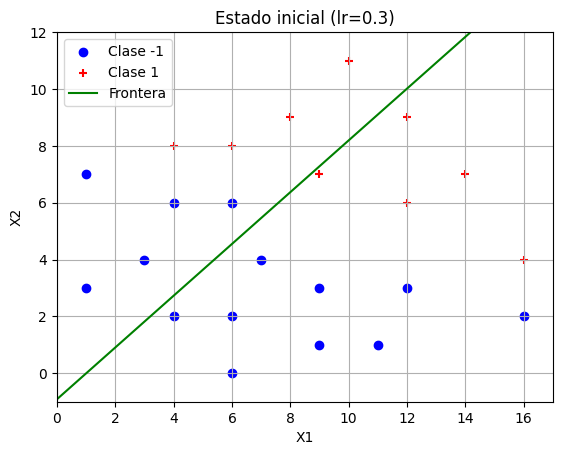

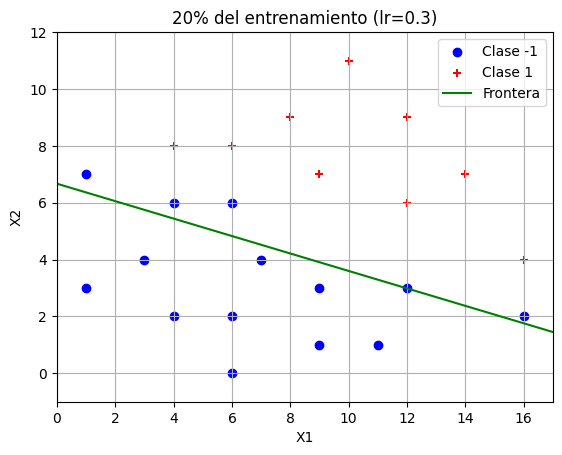

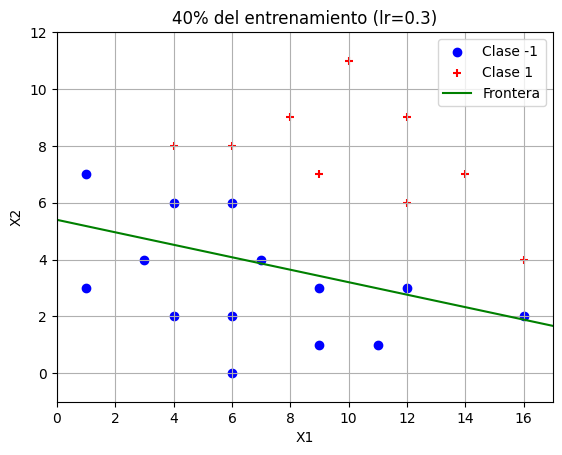

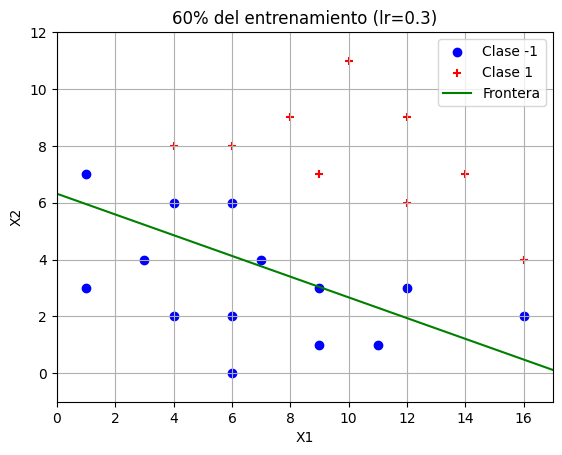

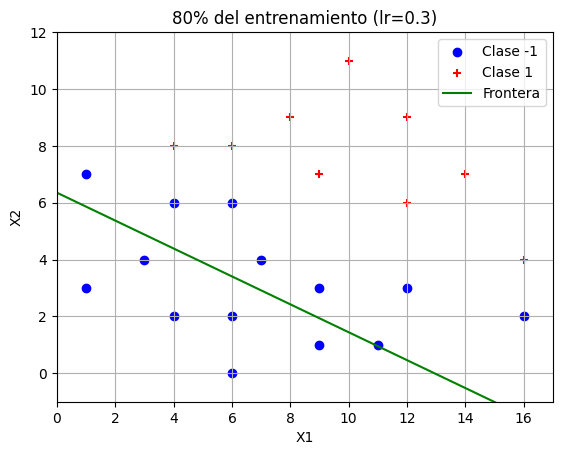

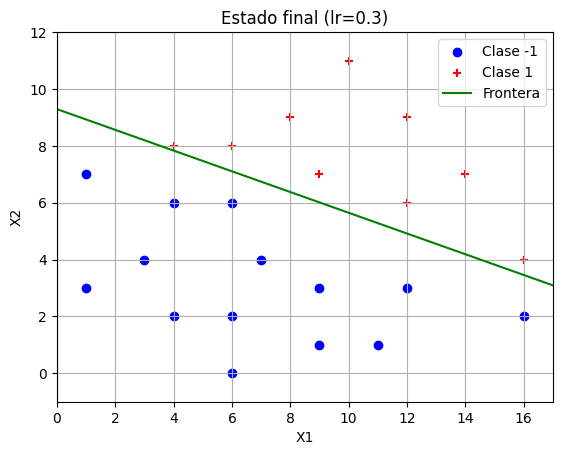

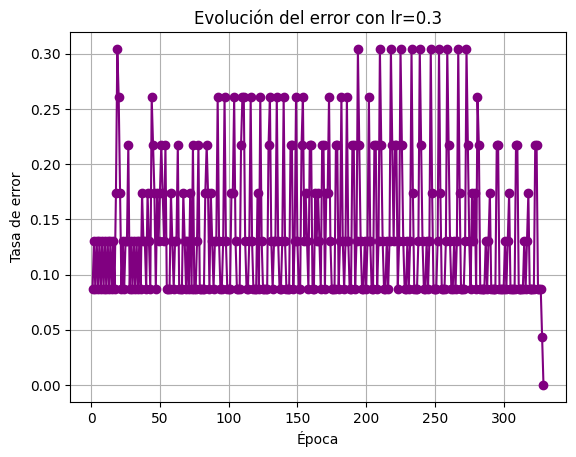

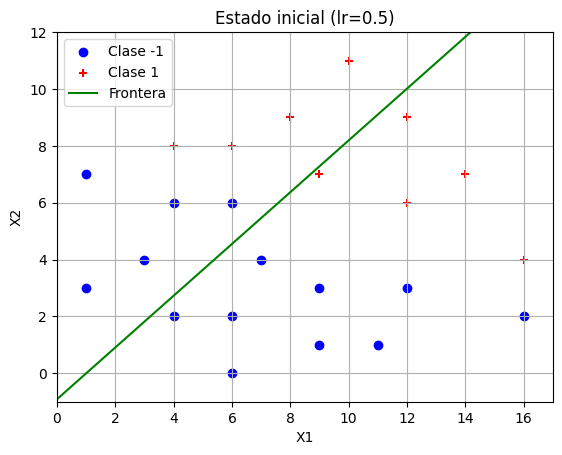

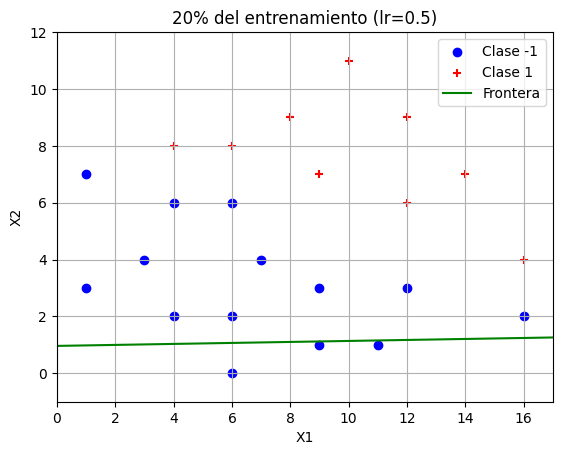

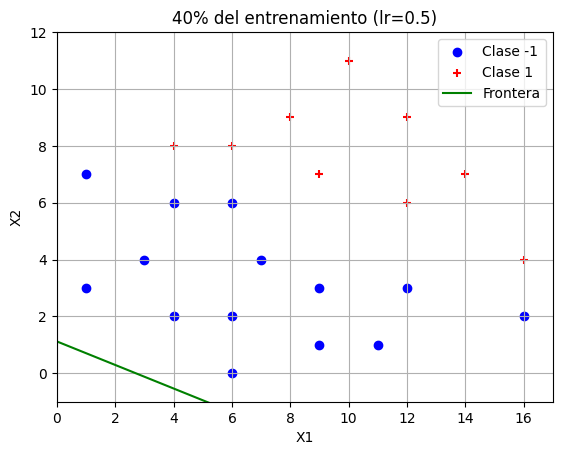

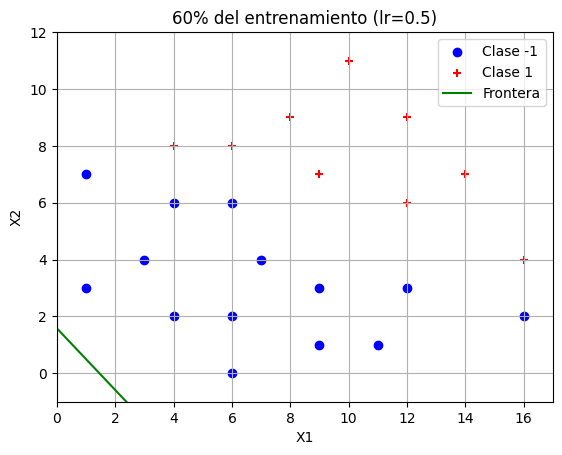

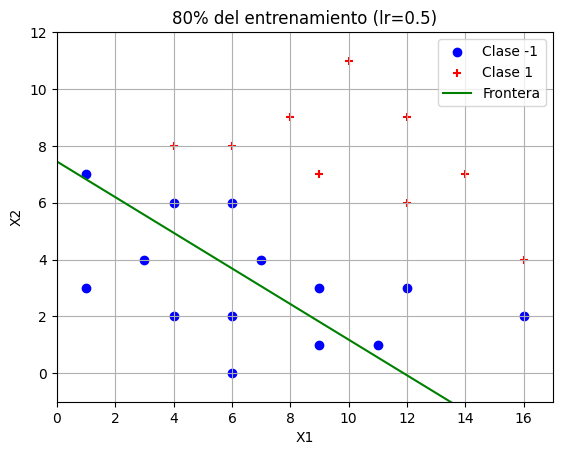

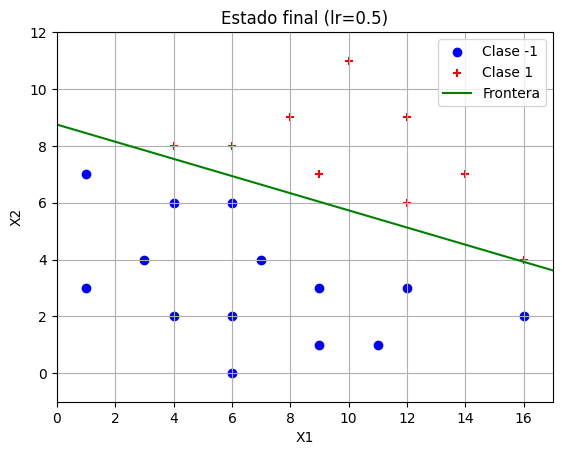

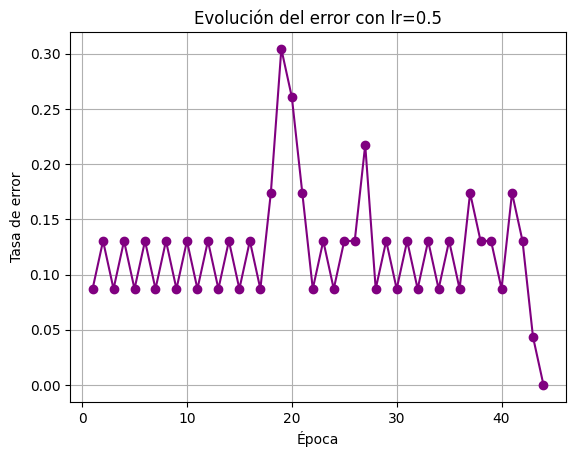

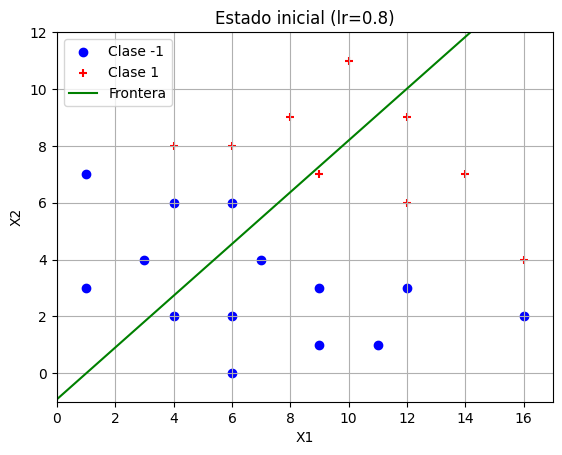

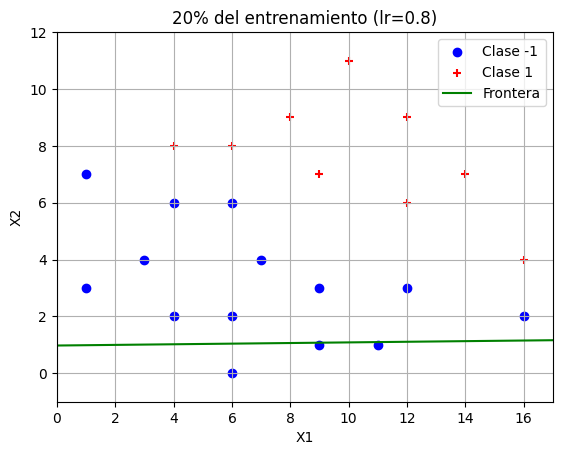

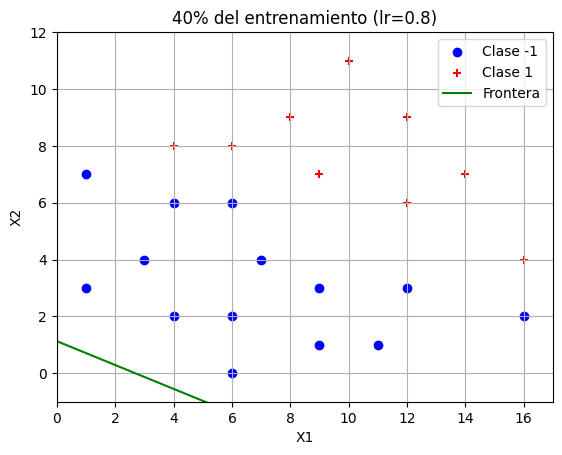

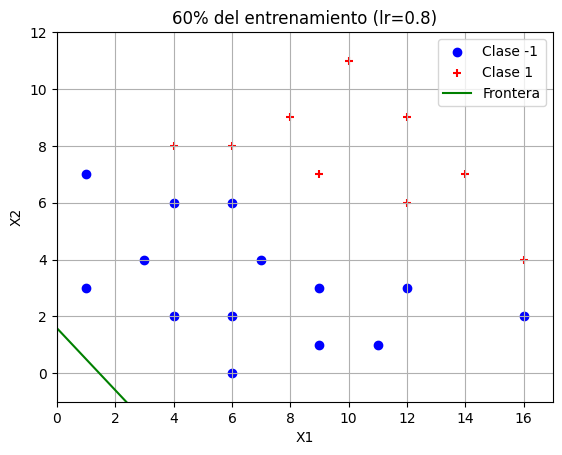

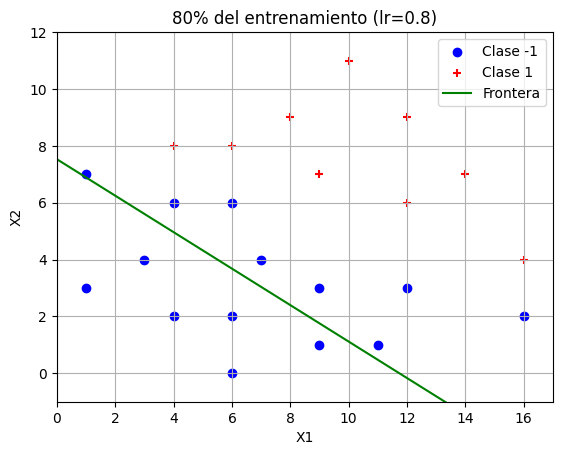

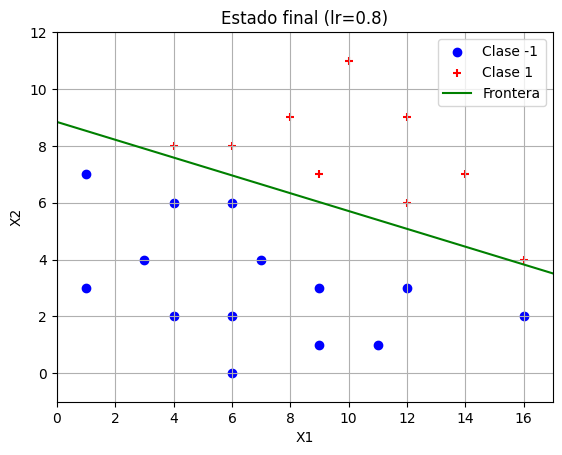

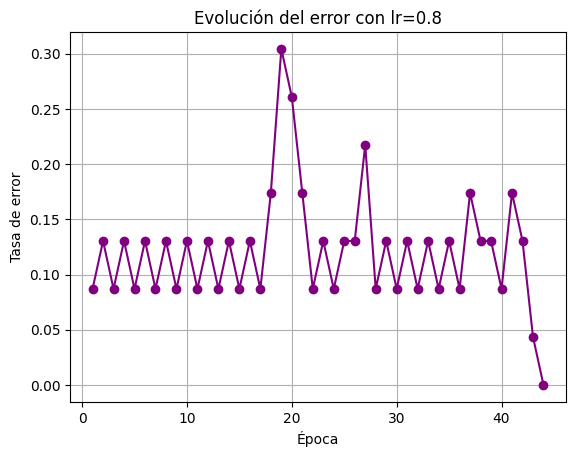

In [ ]:
# Actividad 9.b: Gráficas para lr = 0.3
graficar_seis_estados(X, y, w_comun, W_03, "lr=0.3")
plot_error(E_03, "Evolución del error con lr=0.3")

# Gráficas para lr = 0.5
graficar_seis_estados(X, y, w_comun, W_05, "lr=0.5")
plot_error(E_05, "Evolución del error con lr=0.5")

# Gráficas para lr = 0.8
graficar_seis_estados(X, y, w_comun, W_08, "lr=0.8")
plot_error(E_08, "Evolución del error con lr=0.8")

**Preguntas guía (Fase 9):**
* **Actividad 9.a - ¿Por qué no sería justo comparar las tasas de aprendizaje usando pesos iniciales diferentes?**  
  Porque un experimento podría empezar por suerte con una recta casi correcta y terminar rápido, y no sabríamos si fue gracias a la tasa de aprendizaje o a los pesos iniciales.
* **Actividad 9.b - ¿Qué tasa de aprendizaje permitió alcanzar la convergencia con menos épocas? ¿Eso significa necesariamente que es la mejor tasa de aprendizaje?**  
  Las tasas de `0.5` y `0.8` convergieron en menos épocas (44 épocas frente a 329 con `0.3`). Eso no significa que siempre sean mejores, porque una tasa muy alta da saltos muy grandes y puede causar inestabilidad en otros conjuntos de datos.
* **Actividad 9.c - ¿Los pesos finales son iguales para todas las tasas de aprendizaje? Si son diferentes, ¿por qué pueden producir igualmente una clasificación correcta?**  
  Son diferentes para cada tasa, pero todos clasifican bien porque en el espacio vacío entre las dos clases caben muchas rectas distintas que separan los puntos sin cometer errores.

## Conclusiones y Referencias

### Conclusión
Con el desarrollo de la práctica se comprobó cómo el perceptrón aprende una frontera lineal ajustando sus pesos y el bias cada vez que comete un error de clasificación. Además, al probar distintas tasas de aprendizaje (`0.3`, `0.5` y `0.8`) partiendo de los mismos pesos iniciales, se observó que valores más altos aceleraron el entrenamiento de 329 a 44 épocas obteniendo vectores de pesos distintos, pero logrando en todos los casos separar correctamente las dos clases.

### Referencias
1. F. Rosenblatt, "The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain," *Psychological Review*, vol. 65, no. 6, pp. 386-408, 1958.
2. W. S. McCulloch and W. Pitts, "A Logical Calculus of the Ideas Immanent in Nervous Activity," *Bulletin of Mathematical Biophysics*, vol. 5, pp. 115-133, 1943.
3. H. Ortega Martínez, *Machine Learning Workout: with exercises and practicals in MATLAB*. Quito: Editorial Abya-Yala / Universidad Politécnica Salesiana, 2019.